# SLA and Operations KPI Dashboard
**Tools:** SQL (SQLite), Python (Pandas, Matplotlib), Power BI

**Goal:** Measure how well an IT/operations support team meets its Service Level Agreements (SLAs), find where breaches happen, and flag open tickets at risk of breaching, then prepare clean data for a Power BI dashboard.

> **Data note:** The ticket data below is **synthetic** (generated with a fixed random seed) so the project is reproducible and contains no confidential information. SLA targets: Critical 4h, High 8h, Medium 24h, Low 48h.

## 1. Setup

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 2. Create the ticket dataset
Each ticket has a priority, category, created time and resolved time. Tickets not resolved by the reporting date stay **Open**.

In [2]:
rng = np.random.default_rng(42)
N = 5000

priorities = ["Critical", "High", "Medium", "Low"]
categories = ["Network", "Software", "Hardware", "Access", "Billing"]
sla_hours = {"Critical": 4, "High": 8, "Medium": 24, "Low": 48}

start = pd.Timestamp("2026-01-01")
as_of = pd.Timestamp("2026-04-01 12:00")          # reporting date
span_minutes = int((as_of - start).total_seconds() // 60)

created = start + pd.to_timedelta(rng.integers(0, span_minutes, N), unit="m")
priority = rng.choice(priorities, N, p=[0.08, 0.22, 0.45, 0.25])
category = rng.choice(categories, N, p=[0.22, 0.30, 0.18, 0.20, 0.10])

# Resolution time varies around the SLA target; some categories are slower
target = pd.Series(priority).map(sla_hours).to_numpy()
cat_factor = pd.Series(category).map(
    {"Network": 1.15, "Software": 0.90, "Hardware": 1.30, "Access": 0.80, "Billing": 1.00}
).to_numpy()
res_hours = target * cat_factor * rng.lognormal(mean=-0.15, sigma=0.55, size=N)
resolved = created + pd.to_timedelta(res_hours, unit="h")

tickets = pd.DataFrame({
    "ticket_id": [f"TCK-{i:05d}" for i in range(1, N + 1)],
    "created_at": created,
    "resolved_at": resolved,
    "priority": priority,
    "category": category,
})
tickets["sla_hours"] = tickets["priority"].map(sla_hours)
tickets["status"] = np.where(tickets["resolved_at"] <= as_of, "Resolved", "Open")
tickets.loc[tickets["status"] == "Open", "resolved_at"] = pd.NaT

tickets.to_csv("data/tickets.csv", index=False)
print(f"{len(tickets)} tickets | {tickets['status'].value_counts().to_dict()}")
tickets.head()

5000 tickets | {'Resolved': 4941, 'Open': 59}


,ticket_id,created_at,resolved_at,priority,category,sla_hours,status
0,TCK-00001,2026-01-09 01:51:00,2026-01-09 02:59:06.333526500,Critical,Software,4,Resolved
1,TCK-00002,2026-03-12 01:01:00,2026-03-12 12:42:28.550256342,Medium,Access,24,Resolved
2,TCK-00003,2026-03-01 05:43:00,2026-03-02 09:17:20.878283578,Low,Network,48,Resolved
3,TCK-00004,2026-02-09 17:14:00,2026-02-11 08:54:35.797208700,Low,Software,48,Resolved
4,TCK-00005,2026-02-09 04:30:00,2026-02-09 10:18:15.255847810,High,Hardware,8,Resolved


## 3. Load into SQL
I load the data into SQLite and use SQL for the KPI logic. A view calculates resolution time and whether each resolved ticket met its SLA.

In [3]:
con = sqlite3.connect(":memory:")
tickets.assign(
    created_at=tickets["created_at"].astype(str),
    resolved_at=tickets["resolved_at"].astype(str).replace("NaT", None),
).to_sql("tickets", con, index=False)

con.executescript("""
CREATE VIEW resolved AS
SELECT ticket_id, priority, category, created_at, resolved_at, sla_hours,
       ROUND((julianday(resolved_at) - julianday(created_at)) * 24, 2) AS resolution_hours,
       CASE WHEN (julianday(resolved_at) - julianday(created_at)) * 24 <= sla_hours
            THEN 1 ELSE 0 END AS sla_met
FROM tickets
WHERE status = 'Resolved';
""")

def q(sql, params=None):
    return pd.read_sql_query(sql, con, params=params)

q("SELECT * FROM resolved LIMIT 5")

,ticket_id,priority,category,created_at,resolved_at,sla_hours,resolution_hours,sla_met
0,TCK-00001,Critical,Software,2026-01-09 01:51:00,2026-01-09 02:59:06.333526500,4,1.14,1
1,TCK-00002,Medium,Access,2026-03-12 01:01:00,2026-03-12 12:42:28.550256342,24,11.69,1
2,TCK-00003,Low,Network,2026-03-01 05:43:00,2026-03-02 09:17:20.878283578,48,27.57,1
3,TCK-00004,Low,Software,2026-02-09 17:14:00,2026-02-11 08:54:35.797208700,48,39.68,1
4,TCK-00005,High,Hardware,2026-02-09 04:30:00,2026-02-09 10:18:15.255847810,8,5.80,1


## 4. Headline KPIs

In [4]:
overall = q("""
SELECT COUNT(*)                                   AS resolved_tickets,
       ROUND(100.0 * SUM(sla_met) / COUNT(*), 1)  AS sla_compliance_pct,
       ROUND(AVG(resolution_hours), 1)            AS avg_resolution_hours,
       COUNT(*) - SUM(sla_met)                    AS sla_breaches
FROM resolved
""")
overall

,resolved_tickets,sla_compliance_pct,avg_resolution_hours,sla_breaches
0,4941,60.4,25.2,1956


## 5. SLA compliance by priority

In [5]:
by_priority = q("""
SELECT priority,
       sla_hours,
       COUNT(*)                                   AS tickets,
       ROUND(AVG(resolution_hours), 1)            AS avg_resolution_hours,
       ROUND(100.0 * SUM(sla_met) / COUNT(*), 1)  AS sla_compliance_pct
FROM resolved
GROUP BY priority, sla_hours
ORDER BY sla_hours
""")
by_priority

,priority,sla_hours,tickets,avg_resolution_hours,sla_compliance_pct
0,Critical,4,405,4.1,61.2
1,High,8,1141,8.0,62.7
2,Medium,24,2244,24.3,60.7
3,Low,48,1151,51.3,57.3


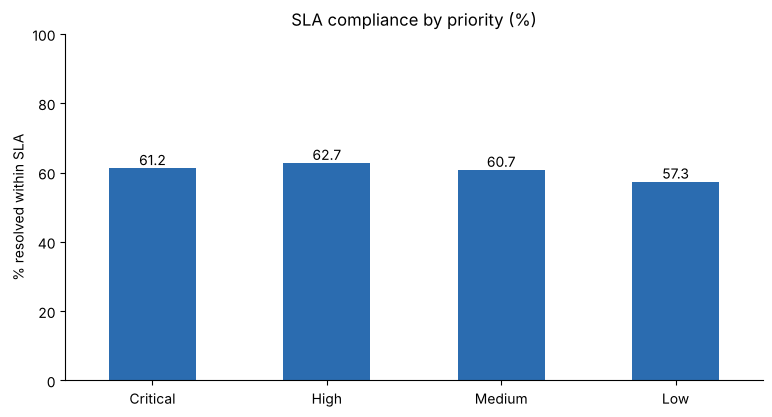

In [6]:
ax = by_priority.plot.bar(x="priority", y="sla_compliance_pct", legend=False, color="#2b6cb0")
ax.set_title("SLA compliance by priority (%)")
ax.set_xlabel("")
ax.set_ylabel("% resolved within SLA")
ax.set_ylim(0, 100)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.xticks(rotation=0)
plt.show()

## 6. SLA compliance by category

In [7]:
by_category = q("""
SELECT category,
       COUNT(*)                                   AS tickets,
       ROUND(AVG(resolution_hours), 1)            AS avg_resolution_hours,
       ROUND(100.0 * SUM(sla_met) / COUNT(*), 1)  AS sla_compliance_pct
FROM resolved
GROUP BY category
ORDER BY sla_compliance_pct
""")
by_category

,category,tickets,avg_resolution_hours,sla_compliance_pct
0,Hardware,917,31.9,43.3
1,Network,1076,28.4,52.0
2,Billing,496,24.1,61.9
3,Software,1471,22.1,67.8
4,Access,981,20.5,73.7


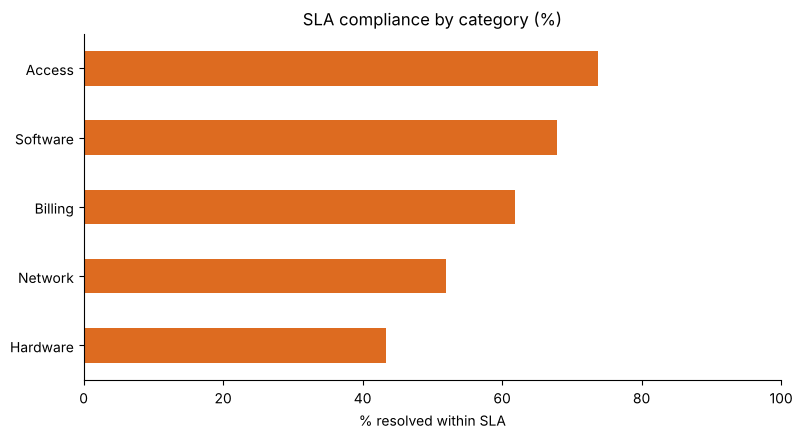

In [8]:
ax = by_category.plot.barh(x="category", y="sla_compliance_pct", legend=False, color="#dd6b20")
ax.set_title("SLA compliance by category (%)")
ax.set_ylabel("")
ax.set_xlabel("% resolved within SLA")
ax.set_xlim(0, 100)
plt.show()

## 7. Where do breaches concentrate? (priority x category)

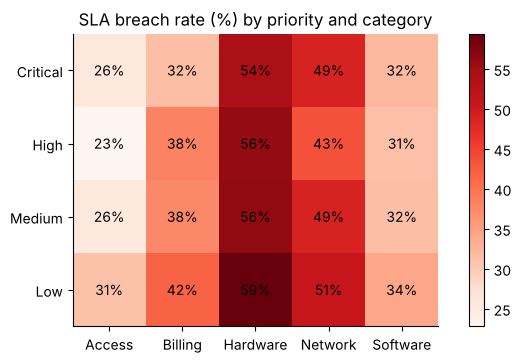

category,Access,Billing,Hardware,Network,Software
priority,,,,,
Critical,25.9,31.6,54.1,48.8,32.2
High,22.8,38.1,55.9,43.4,31.3
Medium,25.5,37.6,56.2,48.7,31.5
Low,31.2,41.7,59.4,50.8,34.2


In [9]:
matrix = q("""
SELECT priority, category,
       ROUND(100.0 * (COUNT(*) - SUM(sla_met)) / COUNT(*), 1) AS breach_rate_pct
FROM resolved
GROUP BY priority, category
""").pivot(index="priority", columns="category", values="breach_rate_pct").loc[priorities]

fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(matrix.values, cmap="Reds")
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f"{matrix.values[i, j]:.0f}%", ha="center", va="center")
ax.set_title("SLA breach rate (%) by priority and category")
fig.colorbar(im, ax=ax)
plt.show()
matrix

## 8. Open tickets at risk of breaching
An open ticket is **At risk** once it has used 75% or more of its SLA time, and **Breached** once it has passed 100%.

In [10]:
at_risk = q("""
SELECT ticket_id, priority, category, created_at, sla_hours,
       ROUND((julianday(:as_of) - julianday(created_at)) * 24, 1)                  AS hours_open,
       ROUND(100.0 * (julianday(:as_of) - julianday(created_at)) * 24 / sla_hours, 0) AS pct_of_sla_used,
       CASE WHEN (julianday(:as_of) - julianday(created_at)) * 24 >= sla_hours
            THEN 'Breached' ELSE 'At risk' END                                      AS flag
FROM tickets
WHERE status = 'Open'
  AND (julianday(:as_of) - julianday(created_at)) * 24 >= 0.75 * sla_hours
ORDER BY pct_of_sla_used DESC
""", params={"as_of": str(as_of)})

print(at_risk["flag"].value_counts().to_dict())
at_risk.head(10)

{'Breached': 16, 'At risk': 7}


,ticket_id,priority,category,created_at,sla_hours,hours_open,pct_of_sla_used,flag
0,TCK-02169,Low,Billing,2026-03-26 17:10:00,48,138.8,289.0,Breached
1,TCK-02828,Low,Network,2026-03-27 09:01:00,48,123.0,256.0,Breached
2,TCK-00965,Low,Hardware,2026-03-27 21:32:00,48,110.5,230.0,Breached
3,TCK-03211,Low,Access,2026-03-28 21:51:00,48,86.1,179.0,Breached
4,TCK-01243,Low,Network,2026-03-29 04:11:00,48,79.8,166.0,Breached
5,TCK-01676,Medium,Billing,2026-03-30 23:58:00,24,36.0,150.0,Breached
6,TCK-04761,Low,Software,2026-03-29 12:35:00,48,71.4,149.0,Breached
7,TCK-00797,Low,Hardware,2026-03-29 15:10:00,48,68.8,143.0,Breached
8,TCK-03944,Low,Network,2026-03-29 17:39:00,48,66.4,138.0,Breached
9,TCK-03912,Low,Network,2026-03-29 20:22:00,48,63.6,133.0,Breached


## 9. Findings

In [11]:
worst_priority = by_priority.sort_values("sla_compliance_pct").iloc[0]
worst_category = by_category.iloc[0]
hot = matrix.stack().sort_values(ascending=False).head(3)

print(f"Overall SLA compliance: {overall.loc[0, 'sla_compliance_pct']}% "
      f"({overall.loc[0, 'sla_breaches']} breaches out of {overall.loc[0, 'resolved_tickets']} resolved tickets)")
print(f"Lowest compliance by priority: {worst_priority['priority']} ({worst_priority['sla_compliance_pct']}%)")
print(f"Lowest compliance by category: {worst_category['category']} ({worst_category['sla_compliance_pct']}%)")
print("Highest breach-rate combinations:")
for (p, c), v in hot.items():
    print(f"  - {p} / {c}: {v}%")
print(f"Open tickets needing follow-up: {len(at_risk)}")

Overall SLA compliance: 60.4% (1956 breaches out of 4941 resolved tickets)
Lowest compliance by priority: Low (57.3%)
Lowest compliance by category: Hardware (43.3%)
Highest breach-rate combinations:
  - Low / Hardware: 59.4%
  - Medium / Hardware: 56.2%
  - High / Hardware: 55.9%
Open tickets needing follow-up: 23


## 10. Export for Power BI
These CSV files are the data source for the dashboard.

In [12]:
tickets_export = q("""
SELECT t.ticket_id, t.priority, t.category, t.status, t.sla_hours,
       t.created_at, t.resolved_at, r.resolution_hours, r.sla_met
FROM tickets t
LEFT JOIN resolved r ON r.ticket_id = t.ticket_id
""")
tickets_export.to_csv("output/powerbi_tickets.csv", index=False)
by_priority.to_csv("output/kpi_by_priority.csv", index=False)
by_category.to_csv("output/kpi_by_category.csv", index=False)
at_risk.to_csv("output/open_tickets_at_risk.csv", index=False)
print(sorted(os.listdir("output")))

['kpi_by_category.csv', 'kpi_by_priority.csv', 'open_tickets_at_risk.csv', 'powerbi_tickets.csv']


## 11. Build the dashboard in Power BI
1. **Get Data > Text/CSV** and load `output/powerbi_tickets.csv`.
2. In Power Query, set `created_at` and `resolved_at` to Date/Time and `sla_met` to Whole Number.
3. Create these measures:
```
Resolved Tickets = CALCULATE(COUNTROWS(powerbi_tickets), powerbi_tickets[status] = "Resolved")
SLA Compliance % = DIVIDE(SUM(powerbi_tickets[sla_met]), [Resolved Tickets])
Avg Resolution Hours = AVERAGE(powerbi_tickets[resolution_hours])
SLA Breaches = [Resolved Tickets] - SUM(powerbi_tickets[sla_met])
```
4. Add visuals: KPI cards (SLA Compliance %, Breaches, Avg Resolution Hours), a bar chart of compliance by priority, a bar chart by category, a matrix of breach rate (priority x category), and a table from `open_tickets_at_risk.csv`.
5. Add slicers for priority and category. Save a screenshot to `screenshots/` for the README.